# Olist Brazilian E-Commerce — продуктовые метрики на реальных данных

Анализ **реального** датасета [Olist (Kaggle)](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce):
99 440 заказов, 96 095 клиентов, сентябрь 2016 — октябрь 2018.

Данные в git не хранятся. Чтобы запустить ноутбук:
```bash
python download_data.py      # скачает CSV через kagglehub (без API-ключа)
```
SQL-версия тех же метрик (CTE, оконные функции) — в `olist_analysis.py`.

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
from pathlib import Path

DATA = Path("data")
required = ["olist_orders_dataset.csv", "olist_order_payments_dataset.csv",
            "olist_customers_dataset.csv", "olist_order_items_dataset.csv"]
missing = [f for f in required if not (DATA / f).exists()]
if missing:
    raise SystemExit(f"Нет файлов: {missing}. Запустите: python download_data.py")

orders = pd.read_csv(DATA / "olist_orders_dataset.csv", parse_dates=["order_purchase_timestamp",
                     "order_delivered_customer_date", "order_estimated_delivery_date"])
payments = pd.read_csv(DATA / "olist_order_payments_dataset.csv")
customers = pd.read_csv(DATA / "olist_customers_dataset.csv")
items = pd.read_csv(DATA / "olist_order_items_dataset.csv")
reviews = pd.read_csv(DATA / "olist_order_reviews_dataset.csv")
print("Данные загружены:", len(orders), "заказов,", len(reviews), "отзывов")

Данные загружены: 99441 заказов, 99224 отзывов


## Ключевые метрики

In [2]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
pay_per_order = payments.groupby("order_id", as_index=False)["payment_value"].sum()
orders = orders.merge(pay_per_order.rename(columns={"payment_value": "order_total"}), on="order_id")
orders = orders.merge(customers[["customer_id", "customer_unique_id"]], on="customer_id")

n_orders = len(orders)
n_customers = orders["customer_unique_id"].nunique()
revenue = orders["order_total"].sum()
aov = orders["order_total"].mean()
ltv_median = orders.groupby("customer_unique_id")["order_total"].sum().median()
repeat = (orders.groupby("customer_unique_id").size() > 1).mean()

print(f"Заказов (с оплатой): {n_orders:,}")
print(f"Уникальных клиентов: {n_customers:,}")
print(f"Выручка: R$ {revenue:,.0f}")
print(f"AOV (средний чек): R$ {aov:.2f}")
print(f"LTV медиана: R$ {ltv_median:.2f}")
print(f"Repeat rate: {repeat:.2%}")

Заказов (с оплатой): 99,440
Уникальных клиентов: 96,095
Выручка: R$ 16,008,872
AOV (средний чек): R$ 160.99
LTV медиана: R$ 108.00
Repeat rate: 3.12%


## 1. Выручка и заказы по месяцам

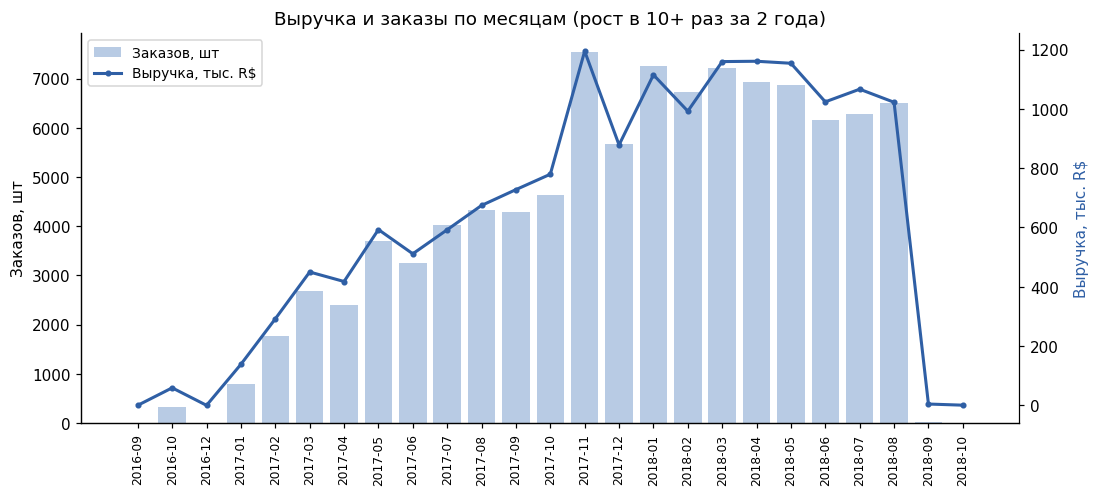

In [3]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
orders["month"] = orders["order_purchase_timestamp"].dt.to_period("M")
monthly = orders.groupby("month").agg(revenue=("order_total", "sum"), n=("order_id", "count"))
monthly.index = monthly.index.astype(str)
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.bar(monthly.index, monthly["n"], color="#B8CBE4", label="Заказов, шт")
ax.set_ylabel("Заказов, шт")
ax2 = ax.twinx()
ax2.plot(monthly.index, monthly["revenue"]/1000, color="#2F5FA5", lw=2, marker="o", ms=3, label="Выручка, тыс. R$")
ax2.set_ylabel("Выручка, тыс. R$", color="#2F5FA5")
ax2.spines["right"].set_visible(True)
ax.set_title("Выручка и заказы по месяцам (рост в 10+ раз за 2 года)", fontsize=12)
ax.tick_params(axis="x", rotation=90, labelsize=8)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=9)
plt.show()

## 2. Топ-10 категорий по выручке

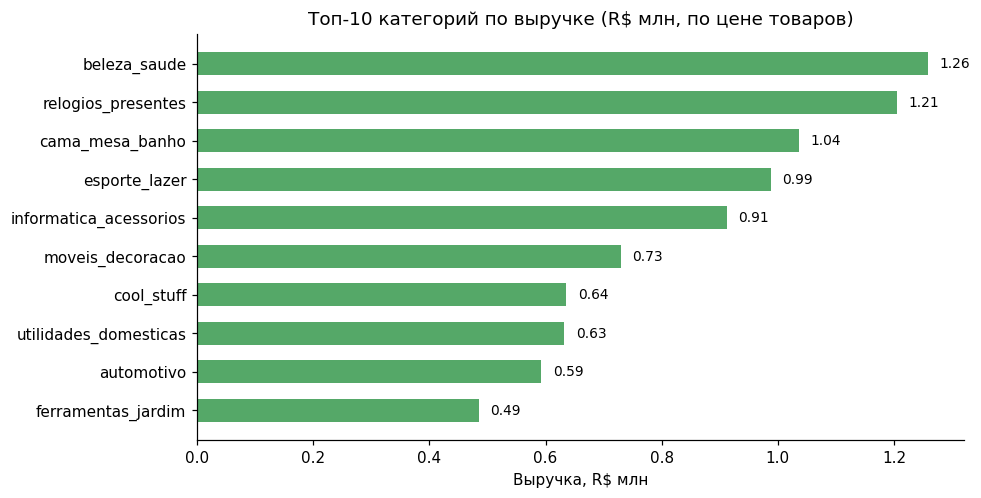

In [4]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
items_o = items.merge(orders[["order_id", "order_total"]], on="order_id")
cat_rev = items_o.merge(
    pd.read_csv(DATA / "olist_products_dataset.csv")[["product_id", "product_category_name"]],
    on="product_id", how="left").groupby("product_category_name")["price"].sum().nlargest(10)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(cat_rev.index[::-1], cat_rev.values[::-1]/1e6, color="#55A868", height=0.6)
for i, v in enumerate(cat_rev.values[::-1]/1e6):
    ax.text(v + 0.02, i, f"{v:.2f}", va="center", fontsize=9)
ax.set_title("Топ-10 категорий по выручке (R$ млн, по цене товаров)", fontsize=12)
ax.set_xlabel("Выручка, R$ млн")
plt.show()

## 3. Скорость доставки

`order_delivered_customer_date − order_purchase_timestamp`: сколько дней шла доставка.

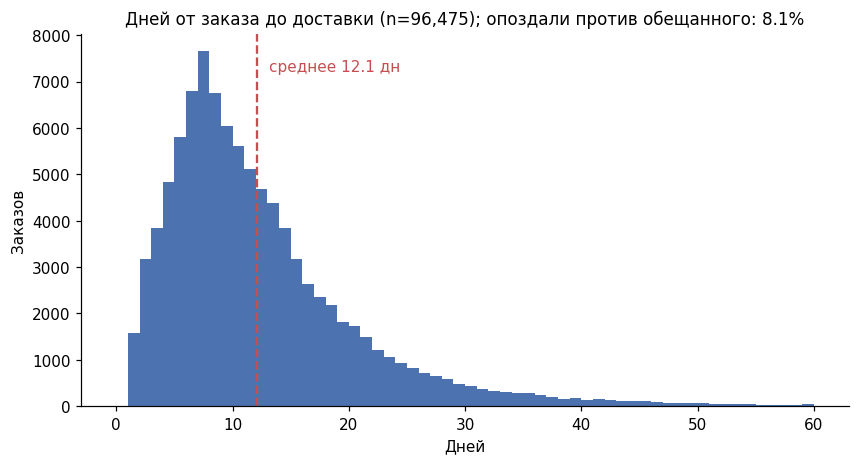

In [5]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
delivered = orders.dropna(subset=["order_delivered_customer_date"]).copy()
delivered["days"] = (delivered["order_delivered_customer_date"] - delivered["order_purchase_timestamp"]).dt.days
late = (delivered["order_delivered_customer_date"] > delivered["order_estimated_delivery_date"]).mean()

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.hist(delivered.loc[delivered["days"].between(0, 60), "days"], bins=60, color="#4C72B0")
ax.axvline(delivered["days"].mean(), color="#C44E52", ls="--", lw=1.5)
ax.text(delivered["days"].mean() + 1, ax.get_ylim()[1]*0.9,
        f"среднее {delivered['days'].mean():.1f} дн", color="#C44E52", fontsize=10)
ax.set_title(f"Дней от заказа до доставки (n={len(delivered):,}); опоздали против обещанного: {late:.1%}", fontsize=11)
ax.set_xlabel("Дней")
ax.set_ylabel("Заказов")
plt.show()

## 4. Отзывы клиентов

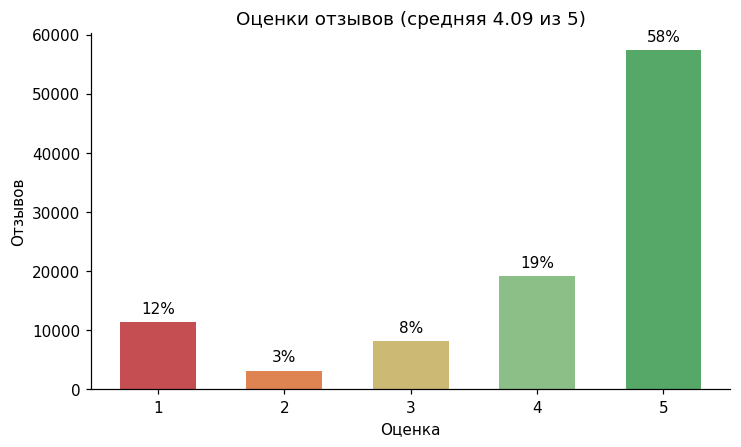

In [6]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
scores = reviews["review_score"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7.5, 4.2))
colors = ["#C44E52", "#DD8452", "#CCB974", "#8CBF88", "#55A868"]
bars = ax.bar(scores.index.astype(str), scores.values, color=colors, width=0.6)
for b, v in zip(bars, scores.values):
    ax.text(b.get_x() + b.get_width()/2, v + 1500, f"{v/len(reviews):.0%}", ha="center", fontsize=10)
ax.set_title(f"Оценки отзывов (средняя {reviews['review_score'].mean():.2f} из 5)", fontsize=12)
ax.set_xlabel("Оценка")
ax.set_ylabel("Отзывов")
plt.show()

## Те же метрики через SQL (демо)

`olist_analysis.py` считает AOV/LTV/retention полностью на SQL (sqlite3 + CTE +
оконные функции). Мини-демонстрация — топ категорий одним CTE-запросом:

In [7]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
import sqlite3
conn = sqlite3.connect(":memory:")
items[["order_id", "price", "product_id"]].to_sql("items", conn, index=False, if_exists="replace")
pd.read_csv(DATA / "olist_products_dataset.csv")[["product_id", "product_category_name"]] \
    .to_sql("products", conn, index=False, if_exists="replace")

query = """
WITH cat_revenue AS (
    SELECT p.product_category_name AS category,
           SUM(i.price) AS revenue,
           COUNT(*) AS items_sold
    FROM items i JOIN products p ON i.product_id = p.product_id
    GROUP BY category
)
SELECT category, ROUND(revenue, 0) AS revenue, items_sold
FROM cat_revenue ORDER BY revenue DESC LIMIT 5
"""
print(pd.read_sql_query(query, conn).to_string(index=False))
conn.close()

              category   revenue  items_sold
          beleza_saude 1258681.0        9670
    relogios_presentes 1205006.0        5991
       cama_mesa_banho 1036989.0       11115
         esporte_lazer  988049.0        8641
informatica_acessorios  911954.0        7827


## Выводы

1. **Масштаб**: 99 440 заказов, R$ 16.0 млн выручки за 2016-09…2018-10; бизнес вырос в разы за два года (видно на графике помесячной динамики).
2. **AOV = R$ 160.99**, медианный чек R$ 105.29 — среднее выше медианы из-за дорогих заказов (лог-нормальное распределение чека).
3. **LTV медиана R$ 108** при repeat rate всего 3.12% — подавляющее большинство клиентов покупает один раз; рост упирается в привлечение, а не в удержание. Ниша для эксперимента: программы повторных покупок в категориях с высоким AOV (relogios_presentes, cool_stuff).
4. **Доставка**: в среднем 12.1 дней (медиана 10), 8.1% доставленных заказов приехали позже обещанной даты. Опоздания — вероятная причина нижней части воронки отзывов (11.5% единиц при средней 4.09).
5. SQL-версия всех метрик с CTE и оконными функциями — `olist_analysis.py`; он же переключается на реальные данные автоматически.